# Grocery Inflation Tracker: Analysis
Charts and statistical tests built on the cleaned StatCan data and the 15-item family basket. All period comparisons use 12-month averages (2019 vs. the latest 12 months) to remove seasonal effects.

In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

df = pd.read_csv("../data/clean/prices_clean.csv", parse_dates=["date"])
basket = pd.read_csv("../data/basket.csv")
os.makedirs("../images", exist_ok=True)

# Chart style: one accent colour, quiet grey axes
BLUE, GREY, INK, MUTED = "#2a78d6", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ececea", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
print(len(df), "price rows |", len(basket), "basket items")

142703 price rows | 15 basket items


In [2]:
def basket_cost(data):
    m = data.merge(basket, on="product")
    m["cost"] = m["price"] * m["quantity"]
    g = m.groupby("date").agg(cost=("cost", "sum"), items=("product", "count"))
    return g[g["items"] == len(basket)]["cost"]   # only months with every item priced

canada = basket_cost(df[df["province"] == "Canada"])
recent_start = canada.index.max() - pd.DateOffset(months=12)

avg_2019 = canada[canada.index.year == 2019].mean()
avg_recent = canada[canada.index > recent_start].mean()
pct = 100 * (avg_recent / avg_2019 - 1)
print(f"2019 avg: ${avg_2019:.2f} | Last 12 months avg: ${avg_recent:.2f} | +{pct:.1f}%")

2019 avg: $83.91 | Last 12 months avg: $111.54 | +32.9%


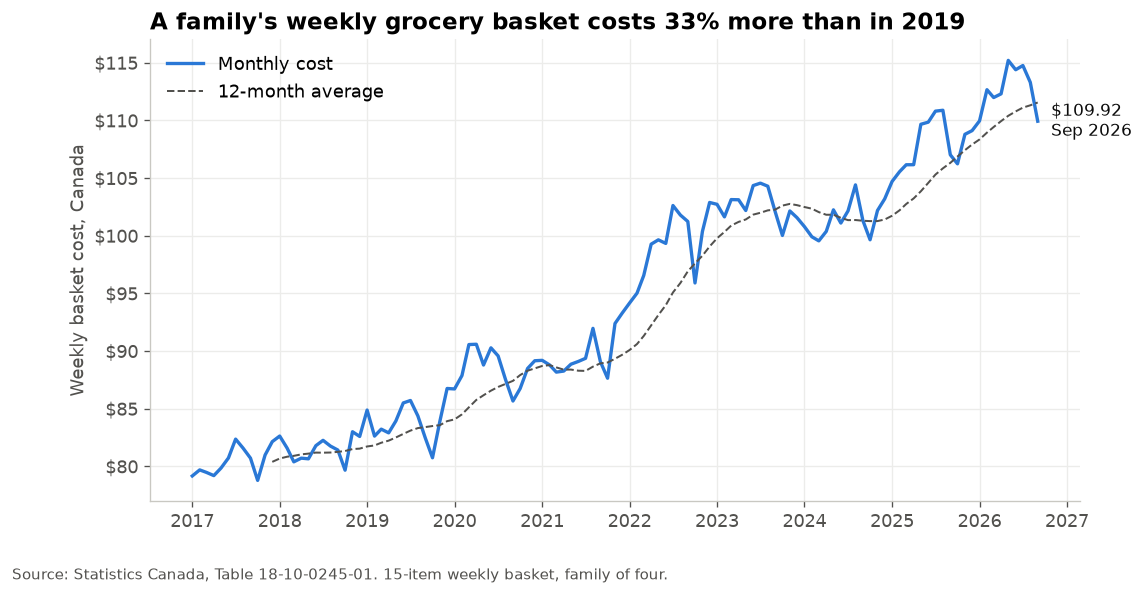

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(canada.index, canada.values, color=BLUE, linewidth=2, label="Monthly cost")
ax.plot(canada.index, canada.rolling(12).mean(), color=MUTED, linewidth=1.2,
        linestyle="--", label="12-month average")

last = canada.index[-1]
ax.annotate(f"${canada.iloc[-1]:.2f}\n{last:%b %Y}", xy=(last, canada.iloc[-1]),
            xytext=(8, 0), textcoords="offset points", va="center", color=INK, fontsize=10)

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_ylabel("Weekly basket cost, Canada")
ax.set_title(f"A family's weekly grocery basket costs {pct:.0f}% more than in 2019")
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, -0.02, "Source: Statistics Canada, Table 18-10-0245-01. 15-item weekly basket, family of four.",
         fontsize=9, color=MUTED)
fig.savefig("../images/01_basket_trend.png", bbox_inches="tight")
plt.show()

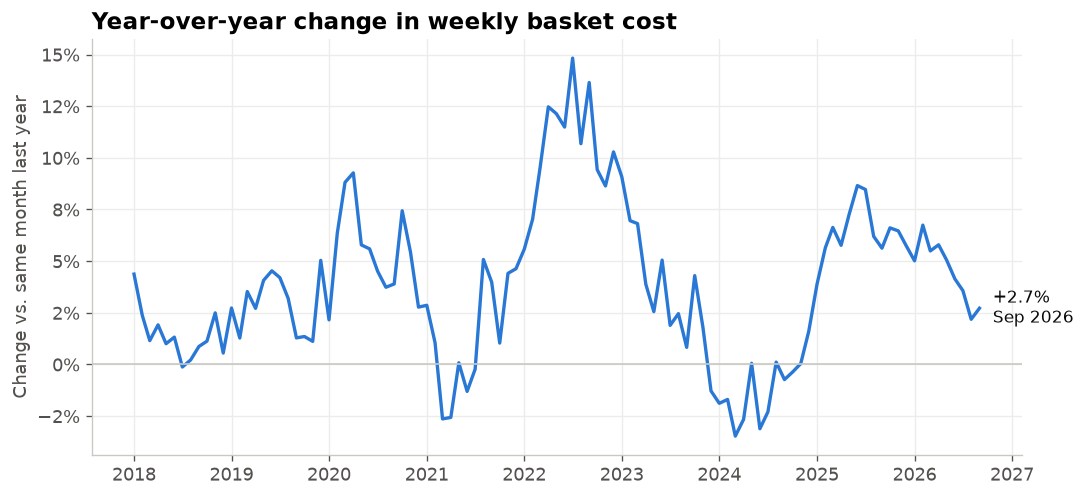

In [4]:
yoy = (canada.pct_change(12) * 100).dropna()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(yoy.index, yoy.values, color=BLUE, linewidth=2)
ax.axhline(0, color=GREY, linewidth=1)
ax.annotate(f"{yoy.iloc[-1]:+.1f}%\n{yoy.index[-1]:%b %Y}", xy=(yoy.index[-1], yoy.iloc[-1]),
            xytext=(8, 0), textcoords="offset points", va="center", color=INK, fontsize=10)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Change vs. same month last year")
ax.set_title("Year-over-year change in weekly basket cost")
fig.savefig("../images/02_yoy_change.png", bbox_inches="tight")
plt.show()

In [5]:
c = df[df["province"] == "Canada"].merge(basket, on="product")
a19 = c[c["date"].dt.year == 2019].groupby("product")["price"].mean()
arc = c[c["date"] > recent_start].groupby("product")["price"].mean()

drivers = basket.set_index("product").assign(avg_2019=a19, avg_recent=arc)
drivers["pct_change"] = 100 * (drivers["avg_recent"] / drivers["avg_2019"] - 1)
drivers["weekly_added"] = (drivers["avg_recent"] - drivers["avg_2019"]) * drivers["quantity"]
drivers["share"] = 100 * drivers["weekly_added"] / drivers["weekly_added"].sum()
drivers = drivers.sort_values("weekly_added", ascending=False)

print("Total weekly increase: $", round(drivers["weekly_added"].sum(), 2))
drivers.round(2)

Total weekly increase: $ 27.63


,quantity,avg_2019,avg_recent,pct_change,weekly_added,share
product,,,,,,
"Ground beef, per kilogram",1.0,9.22,16.08,74.41,6.86,24.83
"Chicken breasts, per kilogram",1.5,11.81,14.58,23.44,4.15,15.02
"Milk, 4 litres",2.0,5.23,6.93,32.48,3.40,12.30
"Eggs, 1 dozen",2.0,3.40,4.80,41.25,2.81,10.16
"Roasted or ground coffee, 340 grams",0.5,5.20,9.39,80.77,2.10,7.59
"Apples, per kilogram",1.5,4.59,5.61,22.28,1.53,5.55
"White bread, 675 grams",2.0,2.87,3.59,25.02,1.44,5.20
"Tomatoes, per kilogram",1.0,4.27,5.51,28.88,1.23,4.47
"Block cheese, 500 grams",1.0,5.85,6.97,19.19,1.12,4.06


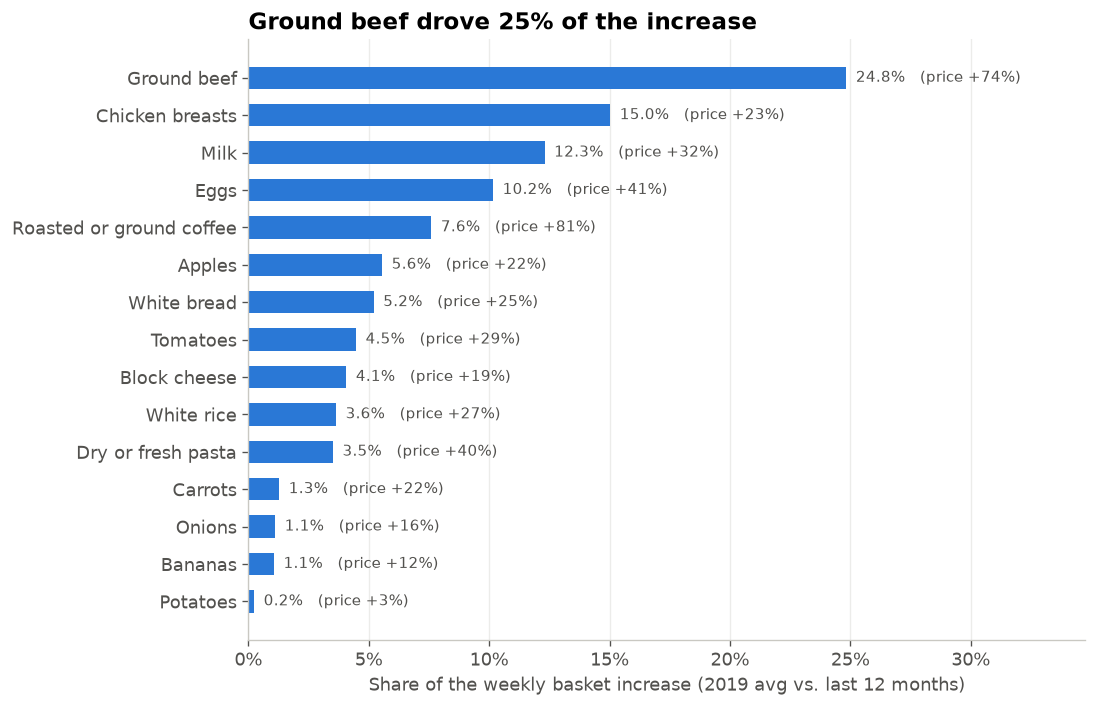

In [6]:
d = drivers.sort_values("share")
labels = d.index.str.split(",").str[0]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(labels, d["share"], color=BLUE, height=0.6)
for y, (s, p) in enumerate(zip(d["share"], d["pct_change"])):
    ax.text(s + 0.4, y, f"{s:.1f}%   (price {p:+.0f}%)", va="center", color=MUTED, fontsize=9)

ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, d["share"].max() * 1.4)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of the weekly basket increase (2019 avg vs. last 12 months)")
ax.set_title(f"{labels[-1]} drove {d['share'].iloc[-1]:.0f}% of the increase")
fig.savefig("../images/03_item_drivers.png", bbox_inches="tight")
plt.show()

In [7]:
mom = canada.pct_change() * 100                      # month-over-month % change
peak = mom["2022-01-01":"2023-12-01"]                # high-inflation period
latest = mom[mom.index > recent_start]               # last 12 months

t, p_t = stats.ttest_ind(peak, latest, equal_var=False, alternative="greater")
u, p_mw = stats.mannwhitneyu(peak, latest, alternative="greater")

print(f"Avg monthly change 2022–23:      {peak.mean():.2f}%  (n={len(peak)})")
print(f"Avg monthly change last 12 mo:   {latest.mean():.2f}%  (n={len(latest)})")
print(f"Welch t-test p = {p_t:.3f} | Mann-Whitney p = {p_mw:.3f}")
print("Significant at 5%" if max(p_t, p_mw) < 0.05 else "Not statistically significant at 5%")

Avg monthly change 2022–23:      0.38%  (n=24)
Avg monthly change last 12 mo:   0.24%  (n=12)
Welch t-test p = 0.415 | Mann-Whitney p = 0.401
Not statistically significant at 5%


In [11]:
for p in skipped:
    g = df[(df["province"] == p) & (df["product"].isin(basket["product"]))]
    m19 = g[g["date"].dt.year == 2019].groupby("product")["date"].nunique()
    mr = g[g["date"] > recent_start].groupby("product")["date"].nunique()
    check = basket.set_index("product").assign(months_2019=m19, months_recent=mr).fillna(0)
    gaps = check[(check["months_2019"] < 12) | (check["months_recent"] < 12)]
    print(f"\n{p}: {len(gaps)} item(s) with gaps")
    print(gaps[["months_2019", "months_recent"]].astype(int).to_string())


Newfoundland and Labrador: 1 item(s) with gaps
                months_2019  months_recent
product                                   
Milk, 4 litres            0              0

Whitehorse, Yukon: 15 item(s) with gaps
                                     months_2019  months_recent
product                                                        
Milk, 4 litres                                 0             12
Eggs, 1 dozen                                  0             12
White bread, 675 grams                         0             12
Block cheese, 500 grams                        0             12
Chicken breasts, per kilogram                  0              0
Ground beef, per kilogram                      0              0
White rice, 2 kilograms                        0             12
Dry or fresh pasta, 500 grams                  0             12
Potatoes, 4.54 kilograms                       0              0
Carrots, 1.36 kilograms                        0              0
Onions, 1.36 k

Monthly changes are noisy and the samples are small (24 vs 12 months), so treat this as indicative.

In [8]:
rows, skipped = [], []
for prov, g in df[df["province"] != "Canada"].groupby("province"):
    cost = basket_cost(g)
    n19 = (cost.index.year == 2019).sum()
    nr = (cost.index > recent_start).sum()
    if n19 == 12 and nr == 12:
        a, r = cost[cost.index.year == 2019].mean(), cost[cost.index > recent_start].mean()
        rows.append((prov, a, r, 100 * (r / a - 1)))
    else:
        skipped.append(prov)

prov = pd.DataFrame(rows, columns=["province", "avg_2019", "avg_recent", "pct_change"]).sort_values("pct_change")
print("Skipped (missing basket items):", skipped or "none")
prov.round(2)

Skipped (missing basket items): ['Newfoundland and Labrador', 'Whitehorse, Yukon', 'Yellowknife, Northwest Territories']


,province,avg_2019,avg_recent,pct_change
7,Quebec,90.19,112.96,25.24
3,New Brunswick,89.55,120.59,34.66
0,Alberta,87.54,118.94,35.87
6,Prince Edward Island,89.64,121.96,36.05
5,Ontario,79.23,108.32,36.72
8,Saskatchewan,83.86,114.93,37.06
4,Nova Scotia,86.65,118.91,37.22
1,British Columbia,88.13,121.39,37.75
2,Manitoba,82.45,114.80,39.25


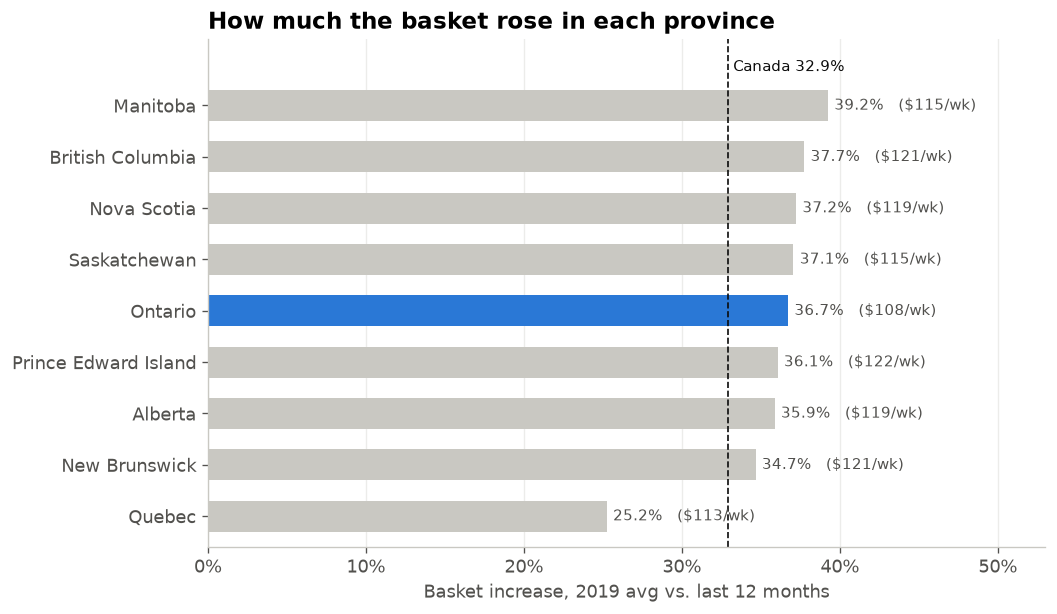

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [BLUE if p == "Ontario" else GREY for p in prov["province"]]
ax.barh(prov["province"], prov["pct_change"], color=colors, height=0.6)
for y, (v, cost) in enumerate(zip(prov["pct_change"], prov["avg_recent"])):
    ax.text(v + 0.4, y, f"{v:.1f}%   (${cost:.0f}/wk)", va="center", color=MUTED, fontsize=9)

ax.axvline(pct, color=INK, linewidth=1, linestyle="--")
ax.text(pct, len(prov) - 0.4, f" Canada {pct:.1f}%", color=INK, fontsize=9, va="bottom")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, prov["pct_change"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Basket increase, 2019 avg vs. last 12 months")
ax.set_title("How much the basket rose in each province")
ax.set_ylim(-0.6, len(prov) + 0.3)
fig.savefig("../images/04_provinces.png", bbox_inches="tight")
plt.show()

## Findings
- Python reproduces the SQL results exactly: basket +32.9%, total weekly increase $27.63.
- Year-over-year inflation: [describe the 2022–23 peak and where it is now].
- Statistical test: average monthly change fell from [X]% (2022–23) to [Y]% (last 12 months), p = [Z].
- Provinces: Ontario rose [X]% vs. Canada's 32.9%. Highest: [province]. Lowest: [province].